# Spin-photon correlation

Build a 2 x 2 correlation matrix between the photon time bin (early/late optical pi pulse) and the spin projection (bright SSR configured for e1/e2). The analysis uses the saved raw traces.

In [7]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_DIR = Path(r"F:\Data\NuclearOps\Qinu\spin_photon_corr_MW\20260928-h21m33s47_spin_photon_corr_MW")

# Inclusive saved sweep numbers (the data normally starts at sweep 0).
# Example: (1, 20) keeps sweeps 1 through 20; None keeps all sweeps.
SWEEP_RANGE = (0, 2) 

# Thresholds from spin_photon_corr_MW.py. Comparisons remain strict.
INITIAL_CSR_MAX = 1       # accept initial check < 1
FINAL_CSR_MIN = 15         # accept final charge check > 3
SSR_BRIGHT_THRESHOLD = 2  # bright SSR when count > 2
PHOTON_THRESHOLD = 0      # photon detected when count > 0

# True keeps only one click in total across the early and late windows.
# False accepts any detection in one window, provided the other is dark.
REQUIRE_EXACTLY_ONE_CLICK = True
# Exclude a whole sweep/SSR acquisition when neither photon window recorded
# any counts, before applying charge or single-click selection.
# Set True to also exclude acquisitions with counts in only one time bin.
REQUIRE_BOTH_PHOTON_BINS = False


In [8]:
with (DATA_DIR / "measurement.json").open() as f:
    metadata = json.load(f)
with (DATA_DIR / "results.json").open() as f:
    results_payload = json.load(f)

assert metadata["format"] == "nuclearops-efficient-traces"
results = pd.DataFrame(results_payload["data"])

# Filter before loading any traces so every plot/statistic uses this selection.
if SWEEP_RANGE is not None:
    first_sweep, last_sweep = SWEEP_RANGE
    if first_sweep > last_sweep:
        raise ValueError("SWEEP_RANGE must have first_sweep <= last_sweep")
    results = results.loc[
        results["sweeps"].between(first_sweep, last_sweep, inclusive="both")
    ].copy().reset_index(drop=True)
if results.empty:
    raise ValueError(f"No acquisitions found for SWEEP_RANGE={SWEEP_RANGE}")
print("Using sweeps:", sorted(results["sweeps"].unique().tolist()))
display(results[["sweeps", "init_state", "SSR_state", "trace"]])

Using sweeps: [0, 1, 2]


,sweeps,init_state,SSR_state,trace
0,0,e1,e1,traces/e38118ced9fd4caf88e4993817b7d29b.npy
1,0,e1,e2,traces/051f448ccb4d4f9e9971d5160f20acbc.npy
2,1,e1,e1,traces/87ca1fc076d54ca7bb82ba8ea65c2a60.npy
3,1,e1,e2,traces/dbd2ac9a6be34552bd94312aa8746854.npy
4,2,e1,e1,traces/c3f0ee7a853d479b9a153c829a907d46.npy
5,2,e1,e2,traces/ef886f2981cd4c9ca4858e173b94f0bf.npy


The five raw values in each repetition follow the measurement script: initial charge check, early photon, late photon, SSR, final charge check. A bright SSR event measures whichever state is named by `SSR_state` for that trace.
Each saved trace is one sweep/SSR acquisition. The zero-count filter uses its
complete raw early and late windows, before postselection, and excludes it
from all subsequent plots and statistics. The other SSR projection in the
same numbered sweep is retained if it has detections.

In the correlation plot, each **N** is the total accepted coincidence events
for that spin/time-bin combination across all retained acquisitions. The
title gives their sum; percentages are separately normalized for exposure.


In [9]:
WINDOWS_PER_SHOT = 5
records = []
diagnostics = []
ssr_counts_by_state = {"e1": [], "e2": []}
csr_counts_all = []

for row in results.itertuples(index=False):
    trace_path = DATA_DIR / row.trace
    raw = np.load(trace_path, mmap_mode="r", allow_pickle=False)
    if raw.size % WINDOWS_PER_SHOT:
        raise ValueError(f"{trace_path.name}: trace length is not divisible by {WINDOWS_PER_SHOT}")
    shots = np.asarray(raw).reshape(-1, WINDOWS_PER_SHOT)
    initial_csr, early_counts, late_counts, ssr_counts, final_csr = shots.T

    early_total = int(early_counts.sum())
    late_total = int(late_counts.sum())
    failed = ((early_total == 0 or late_total == 0) if REQUIRE_BOTH_PHOTON_BINS
              else (early_total == 0 and late_total == 0))
    diagnostic = {
        "sweep": row.sweeps,
        "SSR_state": row.SSR_state,
        "trace": str(row.trace),
        "shots": len(shots),
        "raw_early_counts": early_total,
        "raw_late_counts": late_total,
        "included": not failed,
        "exclusion_reason": ("No counts in at least one photon window" if REQUIRE_BOTH_PHOTON_BINS
                             else "No counts in either photon window") if failed else "",
    }
    diagnostics.append(diagnostic)
    if failed:
        continue

    charge_valid = (initial_csr < INITIAL_CSR_MAX) & (final_csr > FINAL_CSR_MIN)
    ssr_bright = ssr_counts > SSR_BRIGHT_THRESHOLD
    ssr_counts_by_state[row.SSR_state].append(np.asarray(ssr_counts[charge_valid]))
    csr_counts_all.append(np.asarray(final_csr))

    if REQUIRE_EXACTLY_ONE_CLICK:
        early = (early_counts == 1) & (late_counts == 0)
        late = (early_counts == 0) & (late_counts == 1)
    else:
        early_detected = early_counts > PHOTON_THRESHOLD
        late_detected = late_counts > PHOTON_THRESHOLD
        early = early_detected & ~late_detected
        late = ~early_detected & late_detected

    for time_bin, photon_mask in (("early", early), ("late", late)):
        records.append({
            "spin_state": row.SSR_state,
            "time_bin": time_bin,
            "valid_shots": int(charge_valid.sum()),
            "photon_shots": int((charge_valid & photon_mask).sum()),
            "bright_coincidences": int((charge_valid & photon_mask & ssr_bright).sum()),
        })

    diagnostic.update({
        "charge_valid": int(charge_valid.sum()),
        "early_single": int((charge_valid & early).sum()),
        "late_single": int((charge_valid & late).sum()),
        "SSR_bright": int((charge_valid & ssr_bright).sum()),
    })

diagnostics = pd.DataFrame(diagnostics)
display(diagnostics)
excluded = diagnostics.loc[~diagnostics["included"]]
print(f"Excluded {len(excluded)} of {len(diagnostics)} sweep/SSR acquisitions.")
if not excluded.empty:
    display(excluded[["sweep", "SSR_state", "raw_early_counts", "raw_late_counts", "exclusion_reason"]])

,sweep,SSR_state,trace,shots,raw_early_counts,raw_late_counts,included,exclusion_reason,charge_valid,early_single,late_single,SSR_bright
0,0,e1,traces/e38118ced9fd4caf88e4993817b7d29b.npy,100000,30,25,True,,41553,13,13,11237
1,0,e2,traces/051f448ccb4d4f9e9971d5160f20acbc.npy,100000,32,30,True,,40212,15,14,16897
2,1,e1,traces/87ca1fc076d54ca7bb82ba8ea65c2a60.npy,100000,32,35,True,,43586,15,15,11326
3,1,e2,traces/dbd2ac9a6be34552bd94312aa8746854.npy,100000,28,39,True,,45921,15,16,18703
4,2,e1,traces/c3f0ee7a853d479b9a153c829a907d46.npy,100000,43,32,True,,35736,12,12,9717
5,2,e2,traces/ef886f2981cd4c9ca4858e173b94f0bf.npy,100000,37,42,True,,41543,20,13,16594


Excluded 0 of 6 sweep/SSR acquisitions.


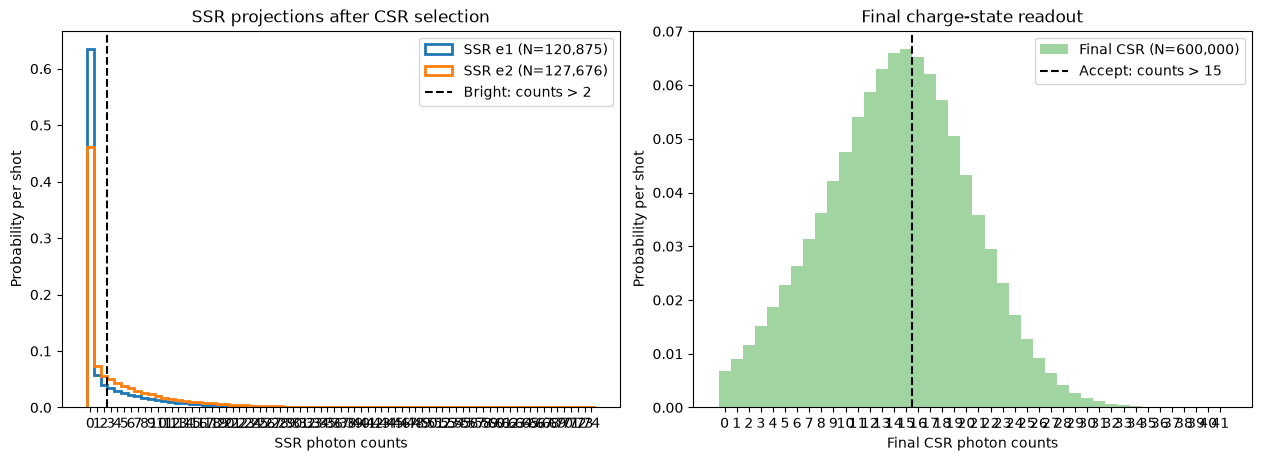

,shots,mean_counts,bright_fraction
e1,120875.0,2.729878,0.267053
e2,127676.0,4.275095,0.408800


In [10]:
# Compare the two bright-state SSR projections before constructing the correlation matrix.
ssr_distributions = {
    state: np.concatenate(parts) if parts else np.array([], dtype=int)
    for state, parts in ssr_counts_by_state.items()
}
csr_distribution = np.concatenate(csr_counts_all) if csr_counts_all else np.array([], dtype=int)
max_ssr_count = max((int(values.max()) for values in ssr_distributions.values() if values.size), default=0)
ssr_bins = np.arange(-0.5, max_ssr_count + 1.5, 1)
max_csr_count = int(csr_distribution.max()) if csr_distribution.size else 0
csr_bins = np.arange(-0.5, max_csr_count + 1.5, 1)

fig, (ax_ssr, ax_csr) = plt.subplots(1, 2, figsize=(12.5, 4.5), constrained_layout=True)
for state, color in (("e1", "tab:blue"), ("e2", "tab:orange")):
    values = ssr_distributions[state]
    ax_ssr.hist(values, bins=ssr_bins, density=True, histtype="step", linewidth=2,
            label=f"SSR {state} (N={values.size:,})", color=color)

ax_ssr.axvline(SSR_BRIGHT_THRESHOLD + 0.5, color="black", linestyle="--", linewidth=1.5,
           label=f"Bright: counts > {SSR_BRIGHT_THRESHOLD}")
ax_ssr.set_xlabel("SSR photon counts")
ax_ssr.set_ylabel("Probability per shot")
ax_ssr.set_title("SSR projections after CSR selection")
ax_ssr.set_xticks(np.arange(0, max_ssr_count + 1))
ax_ssr.legend()

ax_csr.hist(csr_distribution, bins=csr_bins, density=True, histtype="stepfilled",
            alpha=0.45, color="tab:green", label=f"Final CSR (N={csr_distribution.size:,})")
ax_csr.axvline(FINAL_CSR_MIN + 0.5, color="black", linestyle="--", linewidth=1.5,
               label=f"Accept: counts > {FINAL_CSR_MIN}")
ax_csr.set_xlabel("Final CSR photon counts")
ax_csr.set_ylabel("Probability per shot")
ax_csr.set_title("Final charge-state readout")
ax_csr.set_xticks(np.arange(0, max_csr_count + 1))
ax_csr.legend()
plt.show()

pd.DataFrame({
    state: {
        "shots": values.size,
        "mean_counts": values.mean() if values.size else np.nan,
        "bright_fraction": (values > SSR_BRIGHT_THRESHOLD).mean() if values.size else np.nan,
    }
    for state, values in ssr_distributions.items()
}).T

In [11]:
# N counts accepted shots with the specified photon bin AND bright SSR.
# Sum across every retained acquisition; do not average or normalize N.
summary = (pd.DataFrame(records, columns=["spin_state", "time_bin", "valid_shots",
                                         "photon_shots", "bright_coincidences"])
           .astype({"valid_shots": "int64", "photon_shots": "int64", "bright_coincidences": "int64"})
           .groupby(["spin_state", "time_bin"], as_index=False)
           .sum(numeric_only=True))
summary["bright_coincidence_rate"] = (
    summary["bright_coincidences"] / summary["valid_shots"].replace(0, np.nan)
)
display(summary)

state_order = ["e1", "e2"]
bin_order = ["early", "late"]
rates = (summary.pivot(index="spin_state", columns="time_bin",
                       values="bright_coincidence_rate")
         .reindex(index=state_order, columns=bin_order))
counts = (summary.pivot(index="spin_state", columns="time_bin",
                        values="bright_coincidences")
          .reindex(index=state_order, columns=bin_order).fillna(0).astype(int))
total_events = int(counts.to_numpy().sum())
assert total_events == sum(record["bright_coincidences"] for record in records)
print(f"Total accepted coincidence events (sum of plotted N): {total_events:,}")

# The e1 and e2 projections were acquired in separate runs. Normalize each
# photon-bin column after correcting each cell by its number of valid shots.
correlation = rates.div(rates.sum(axis=0).replace(0, np.nan), axis=1)
correlation

,spin_state,time_bin,valid_shots,photon_shots,bright_coincidences,bright_coincidence_rate
0,e1,early,120875,40,11,0.000091
1,e1,late,120875,40,25,0.000207
2,e2,early,127676,50,27,0.000211
3,e2,late,127676,43,7,0.000055


Total accepted coincidence events (sum of plotted N): 70


time_bin,early,late
spin_state,,
e1,0.300861,0.790461
e2,0.699139,0.209539


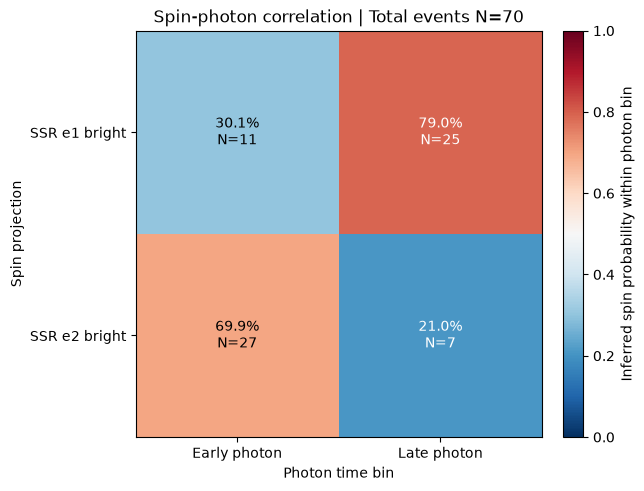

In [12]:
fig, ax = plt.subplots(figsize=(6.2, 4.8), constrained_layout=True)
image = ax.imshow(correlation.to_numpy(), vmin=0, vmax=1, cmap="RdBu_r", aspect="equal")
ax.set_xticks(range(2), ["Early photon", "Late photon"])
ax.set_yticks(range(2), ["SSR e1 bright", "SSR e2 bright"])
ax.set_xlabel("Photon time bin")
ax.set_ylabel("Spin projection")
ax.set_title(f"Spin-photon correlation | Total events N={total_events:,}")

for i, state in enumerate(state_order):
    for j, time_bin in enumerate(bin_order):
        value = correlation.loc[state, time_bin]
        count = int(counts.loc[state, time_bin])
        color = "white" if np.isfinite(value) and (value < 0.25 or value > 0.75) else "black"
        probability = f"{value:.1%}" if np.isfinite(value) else "No data"
        ax.text(j, i, f"{probability}\nN={count:,}", ha="center", va="center", color=color)

cbar = fig.colorbar(image, ax=ax, ticks=np.linspace(0, 1, 6))
cbar.set_label("Inferred spin probability within photon bin")
plt.show()

In [77]:
# Optional scalar contrast: +1 means early->e2 and late->e1; -1 is reversed.
contrast = 0.5 * (
    correlation.loc["e2", "early"]
    + correlation.loc["e1", "late"]
    - correlation.loc["e1", "early"]
    - correlation.loc["e2", "late"]
)
print(f"Early-e2 / late-e1 correlation contrast: {contrast:.4f}")

Early-e2 / late-e1 correlation contrast: 0.8153
